# ECGR 6119 / 8119 — Applied AI Midterm: Dogs vs Cats SRGAN

Final submission. Model A uses 128×128 RGB images; Model B uses SRGAN reconstruction from 32×32 to 128×128. Stratified 70/30 outer split; 15% of the training partition is validation. GAN fitting excludes validation and test images.


## Reproduction and saved results

Training is disabled by default. Read the preserved outputs without execution, or run in Google Colab after restoring the Drive dependencies. All outputs are historical records from the uploaded notebook; no training was executed during editing.

Dataset: `/content/drive/MyDrive/Colab_Assignment1_AAI/dogs-vs-cats-classification/archive.zip`, extracting to `/content/dataset/dogs-vs-cats-classification/{train,validation,test}/{cats,dogs}`. Edit ARCHIVE, DATA and OUT if necessary. The dataset is not embedded.

Artifacts: `/content/drive/MyDrive/ECGR6119_SR_GAN_midterm` must contain `model_a.keras`, `model_b.keras`, `sr_generator.keras`, `metrics.json`, `split_manifest.csv`, the result/example PNGs, and `gan_checkpoints/ckpt-150.index` plus **all** `ckpt-150.data-*` shards. Keep checkpoint metadata for optional automatic training resume. Loading uses the explicit epoch-150 checkpoint and the exact `epoch/gen/disc/gopt/dopt` keys, avoiding generator Lambda deserialization. Missing weights never trigger automatic retraining.

Dependencies: Colab, TensorFlow/Keras, NumPy, Pillow, scikit-learn and Matplotlib. The saved environment output records TensorFlow's observed version; a complete original version lockfile was not supplied. ImageNet weights require internet for optional classifier/VGG training. The successful Pillow EXIF transpose, RGB conversion and bicubic loader is unchanged. Original artifacts and dataset ordering are necessary for exact reproduction; hardware and library changes may affect retraining.

Training partition: 17,451 (including validation); held-out test: 7,479. Cats=0, dogs=1; threshold=0.5; F1 is binary F1 for dogs. SRGAN completed 150 epochs. Model B's code specifies five classifier epochs. Earlier original notebook versions contain Model A's training code with epochs=5 and best-validation-loss checkpoint selection. The final notebook preserves that five-epoch configuration. One earlier version contains a partial first-epoch log; a complete Model A training history is not available.

| Model | Accuracy | F1 | ROC-AUC |
|---|---:|---:|---:|
| A | 0.9733921647279048 | 0.973519627411843 | 0.9970854958868993 |
| B | 0.9368899585506084 | 0.9371337240277038 | 0.9846403573721523 |

Model A exceeds B by approximately 3.65 percentage points in accuracy. This comparison does not isolate SRGAN benefit against a low-resolution/bicubic classifier baseline. Dataset and saved-artifact access links are provided in the repository README; the original dataset publisher/license is not recorded.


## 1. Environment and paths

In [ ]:
import os, random, json, csv, math
from pathlib import Path
import numpy as np, tensorflow as tf, matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from google.colab import drive

drive.mount('/content/drive')
SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__, 'GPU:', tf.config.list_physical_devices('GPU'))
# GPU recommended for evaluation; optional training should use a GPU.
ARCHIVE=Path('/content/drive/MyDrive/Colab_Assignment1_AAI/dogs-vs-cats-classification/archive.zip')
DATA=Path('/content/dataset/dogs-vs-cats-classification')
OUT=Path('/content/drive/MyDrive/ECGR6119_SR_GAN_midterm')
OUT.mkdir(parents=True,exist_ok=True)
assert ARCHIVE.exists(), f'Dataset archive not found: {ARCHIVE}'

TRAIN_MODEL_A = False
TRAIN_SRGAN = False
TRAIN_MODEL_B = False
RUN_EVALUATION = False
CLASSIFIER_EPOCHS = 5
if not TRAIN_MODEL_A:
    assert (OUT/'model_a.keras').is_file(), 'Restore model_a.keras to OUT'
if not TRAIN_MODEL_B:
    assert (OUT/'model_b.keras').is_file(), 'Restore model_b.keras to OUT'
if not TRAIN_SRGAN:
    assert (OUT/'gan_checkpoints/ckpt-150.index').is_file(), 'Restore epoch-150 checkpoint'
    assert list((OUT/'gan_checkpoints').glob('ckpt-150.data-*')), 'Restore all checkpoint data shards'


Mounted at /content/drive
TensorFlow: 2.21.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import zipfile
if not DATA.exists():
    with zipfile.ZipFile(ARCHIVE) as z: z.extractall('/content/dataset')
print('Dataset folders:', list(DATA.iterdir()))


Dataset folders: [PosixPath('/content/dataset/dogs-vs-cats-classification/validation'), PosixPath('/content/dataset/dogs-vs-cats-classification/dataset_info.csv'), PosixPath('/content/dataset/dogs-vs-cats-classification/test'), PosixPath('/content/dataset/dogs-vs-cats-classification/train')]


## 2. Collect, validate, and stratify **70/30**
Reuse all original Assignment 1 image files from train/validation/test, then apply a fresh deterministic stratified split. Do **not** use the original split when comparing models. Files that PIL cannot read are excluded. The optional duplicate-content filter prevents identical bytes from appearing across splits.

In [ ]:
import hashlib
rows=[]; seen_hashes=set(); skipped=0; duplicates=0
for class_id, class_name in enumerate(['cats','dogs']):
    for old_split in ['train','validation','test']:
        folder=DATA/old_split/class_name
        if not folder.exists(): continue
        for p in sorted(folder.iterdir()):
            if p.suffix.lower() not in ('.jpg','.jpeg','.png','.bmp','.webp'):continue
            try:
                with Image.open(p) as im: im.verify()
                h=hashlib.sha256(p.read_bytes()).hexdigest()
                if h in seen_hashes: duplicates+=1; continue
                seen_hashes.add(h); rows.append((str(p),class_id))
            except Exception: skipped+=1
assert len(rows)>100, 'Too few images. Inspect archive folder structure.'
paths=np.array([x[0] for x in rows]); labels=np.array([x[1] for x in rows],dtype=np.int32)
p_train,p_test,y_train,y_test=train_test_split(paths,labels,test_size=0.30,stratify=labels,random_state=SEED)
p_fit,p_val,y_fit,y_val=train_test_split(p_train,y_train,test_size=0.15,stratify=y_train,random_state=SEED)
print('Total usable:',len(paths),'train partition:',len(p_train),'(fit:',len(p_fit),'val:',len(p_val),')','test:',len(p_test),'bad:',skipped,'exact duplicates:',duplicates)
print('Class labels: cats=0, dogs=1')
manifest_path=OUT/'split_manifest.csv'
if manifest_path.exists():
    with open(manifest_path,newline='') as f: saved=list(csv.DictReader(f))
    expected={(str(p),int(y),name) for name,pp,yy in [('train',p_fit,y_fit),('validation',p_val,y_val),('test',p_test,y_test)] for p,y in zip(pp,yy)}
    actual={(r['relative_or_absolute_path'],int(r['label']),r['split']) for r in saved}
    assert actual==expected, 'Dataset differs from saved split manifest; inspect before continuing'
else:
    print('Original manifest unavailable; saving reconstructed split')
    with open(manifest_path,'w',newline='') as f:

        w=csv.writer(f);w.writerow(['relative_or_absolute_path','label','split'])
        for name,pp,yy in [('train',p_fit,y_fit),('validation',p_val,y_val),('test',p_test,y_test)]:
            w.writerows((str(p),int(y),name) for p,y in zip(pp,yy))


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Total usable: 24930 train partition: 17451 (fit: 14833 val: 2618 ) test: 7479 bad: 0 exact duplicates: 0
Class labels: cats=0, dogs=1


## 3. Transformation and sample images
The classifier uses MobileNetV2 `preprocess_input` after augmentation. The GAN uses pixels in **[-1, 1]** (tanh output); 128×128 target images are paired with bicubic-downsampled 32×32 inputs.

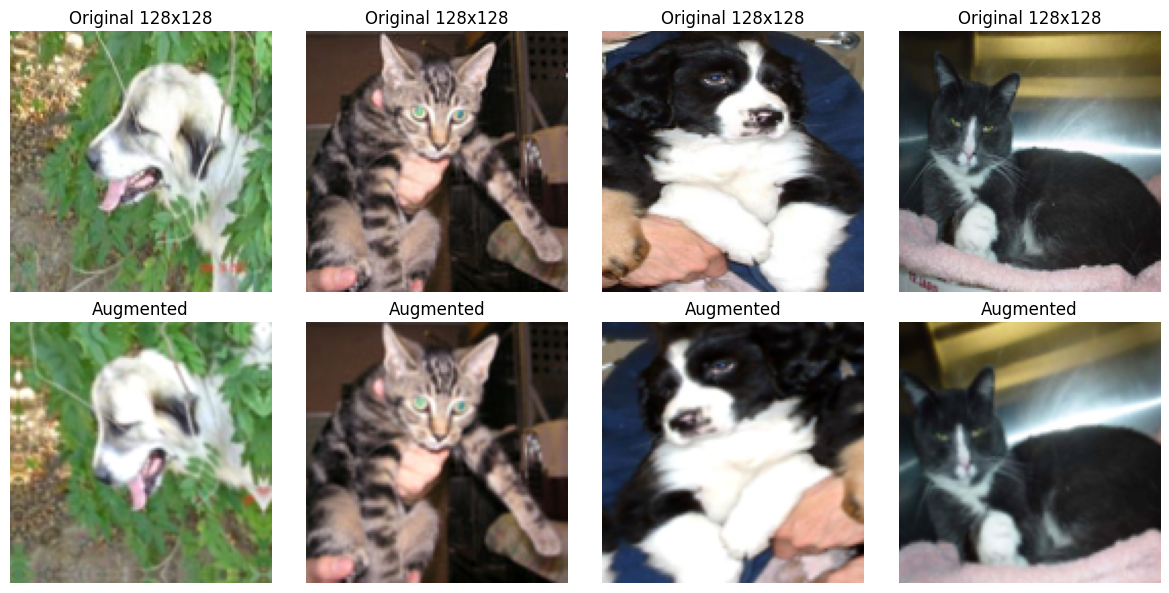

RGB image loading successful
Training images: 14833
Validation images: 2618
Testing images: 7479


In [ ]:

AUTOTUNE = tf.data.AUTOTUNE
BS_CLASSIFIER = 32
BS_GAN = 16

# Use Pillow to handle unusual image formats and color channels
def read_image_with_pillow(path):
    from PIL import Image, ImageOps
    import numpy as np
    import io

    filepath = path.numpy().decode("utf-8")

    with Image.open(filepath) as img:
        img = ImageOps.exif_transpose(img)
        img = img.convert("RGB")
        img = img.resize((128, 128), Image.Resampling.BICUBIC)
        return np.asarray(img, dtype=np.float32)

def load_rgb(path, label):
    image = tf.py_function(
        func=read_image_with_pillow,
        inp=[path],
        Tout=tf.float32
    )
    image.set_shape([128, 128, 3])
    return image, tf.cast(label, tf.float32)

def make_ds(pp, yy, batch, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((pp, yy))

    if shuffle:
        ds = ds.shuffle(
            min(len(pp), 5000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_rgb,
        num_parallel_calls=AUTOTUNE
    )

    return ds.batch(batch).prefetch(AUTOTUNE)

# Create datasets
train_cls = make_ds(p_fit, y_fit, BS_CLASSIFIER, True)
val_cls = make_ds(p_val, y_val, BS_CLASSIFIER)
test_cls = make_ds(p_test, y_test, BS_CLASSIFIER)

# Image augmentation
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.10),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
])

# Display original and augmented images
xb, yb = next(iter(train_cls))
augmented = augment(xb[:4], training=True)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for j in range(4):
    axes[0, j].imshow(
        tf.cast(xb[j], tf.uint8)
    )
    axes[0, j].set_title("Original 128x128")

    axes[1, j].imshow(
        tf.cast(
            tf.clip_by_value(augmented[j], 0, 255),
            tf.uint8
        )
    )
    axes[1, j].set_title("Augmented")

    for i in range(2):
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig(OUT / "transform_examples.png")
plt.show()

print("RGB image loading successful")
print("Training images:", len(p_fit))
print("Validation images:", len(p_val))
print("Testing images:", len(p_test))


## 4. Model A — pretrained MobileNetV2, 128×128

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers

def make_classifier(name):
    base=MobileNetV2(input_shape=(128,128,3),weights='imagenet',include_top=False)
    base.trainable=False
    inp=layers.Input((128,128,3)); x=augment(inp)
    x=preprocess_input(x);x=base(x,training=False)
    x=layers.GlobalAveragePooling2D()(x);x=layers.Dropout(0.2)(x)
    out=layers.Dense(1,activation='sigmoid')(x)
    net=tf.keras.Model(inp,out,name=name)
    net.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='binary_crossentropy',metrics=['accuracy'])
    return net


In [ ]:
# Original five-epoch training configuration recovered from earlier notebooks.
# Complete historical fit output is unavailable; saved results are preserved.
if TRAIN_MODEL_A:
    model_a = make_classifier('model_a')
    history_a = model_a.fit(
        train_cls, validation_data=val_cls, epochs=CLASSIFIER_EPOCHS,
        callbacks=[tf.keras.callbacks.ModelCheckpoint(
            str(OUT/'model_a.keras'), monitor='val_loss', save_best_only=True)])
model_a = tf.keras.models.load_model(OUT/'model_a.keras', compile=False)
print('Model A saved:', (OUT/'model_a.keras').exists())
print('Location:', OUT/'model_a.keras')


Model A saved: True
Location: /content/drive/MyDrive/ECGR6119_SR_GAN_midterm/model_a.keras


## 5. SRGAN — 32×32 → 128×128
Generator: residual blocks + two PixelShuffle upsampling stages (2× each). Discriminator: CNN binary real/fake logits. Generator loss = pixel L1 + VGG19 perceptual + adversarial loss. This is an **SRGAN-style baseline**, not a claimed exact reproduction of all original paper hyperparameters.

In [ ]:
def res_block(x,filters=64):
    skip=x
    x=layers.Conv2D(filters,3,padding='same')(x);x=layers.BatchNormalization()(x);x=layers.PReLU(shared_axes=[1,2])(x)
    x=layers.Conv2D(filters,3,padding='same')(x);x=layers.BatchNormalization()(x)
    return layers.Add()([skip,x])

def make_generator():
    inp=layers.Input((32,32,3));x=layers.Conv2D(64,9,padding='same')(inp)
    x=layers.PReLU(shared_axes=[1,2])(x);skip=x
    for _ in range(8):x=res_block(x)
    x=layers.Conv2D(64,3,padding='same')(x);x=layers.BatchNormalization()(x)
    x=layers.Add()([x,skip])
    for _ in range(2):
        x=layers.Conv2D(256,3,padding='same')(x)
        x=layers.Lambda(lambda t:tf.nn.depth_to_space(t,2))(x)
        x=layers.PReLU(shared_axes=[1,2])(x)
    output=layers.Conv2D(3,9,padding='same',activation='tanh')(x)
    return tf.keras.Model(inp,output,name='sr_generator')

def make_discriminator():
    inp=layers.Input((128,128,3));x=inp
    for i,filters in enumerate([64,64,128,128,256,256,512,512]):
        x=layers.Conv2D(filters,3,strides=(1 if i%2==0 else 2),padding='same')(x)
        if i:x=layers.BatchNormalization()(x)
        x=layers.LeakyReLU(negative_slope=.2)(x)
    x=layers.Flatten()(x);x=layers.Dense(256)(x);x=layers.LeakyReLU(negative_slope=.2)(x)
    return tf.keras.Model(inp,layers.Dense(1)(x),name='sr_discriminator')

generator=make_generator();discriminator=make_discriminator()
print('Generator output:',generator.output_shape)


Generator output: (None, 128, 128, 3)


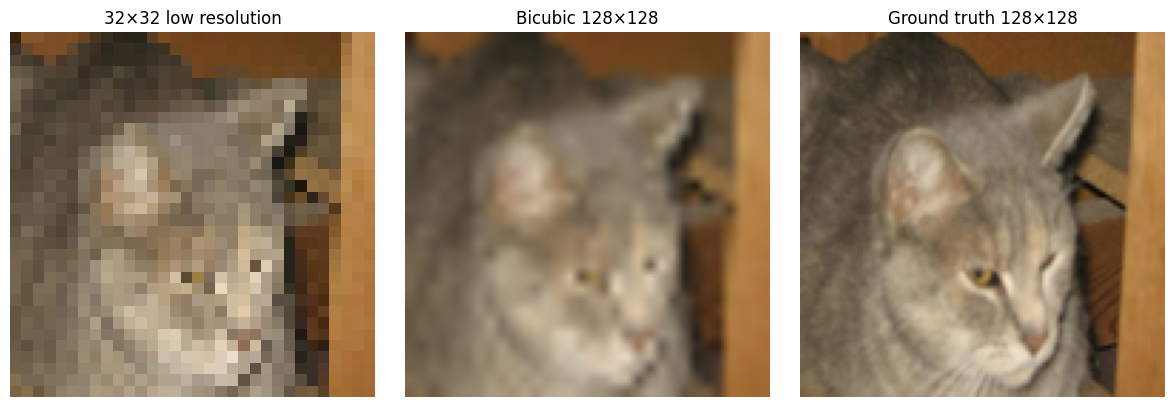

In [ ]:
def gan_pair(img,label):
    hr=(img/127.5)-1.
    lr=tf.image.resize(hr,[32,32],method='bicubic')
    lr=tf.clip_by_value(lr,-1.,1.)
    return lr,hr
# Reuse the training partition only — not validation or test
sr_train=make_ds(p_fit,y_fit,BS_GAN,True).unbatch().map(gan_pair,num_parallel_calls=AUTOTUNE).batch(BS_GAN).prefetch(AUTOTUNE)
sr_val=make_ds(p_val,y_val,4).unbatch().map(gan_pair,num_parallel_calls=AUTOTUNE).batch(4).take(1)
lo,hi=next(iter(sr_val))
fig,axes=plt.subplots(1,3,figsize=(12,4))
axes[0].imshow((lo[0].numpy()+1)/2);axes[0].set_title('32×32 low resolution')
axes[1].imshow(tf.image.resize((lo[0]+1)/2,[128,128]).numpy());axes[1].set_title('Bicubic 128×128')
axes[2].imshow((hi[0].numpy()+1)/2);axes[2].set_title('Ground truth 128×128')
for ax in axes:ax.axis('off')
plt.tight_layout();plt.savefig(OUT/'resolution_examples.png');plt.show()


In [ ]:
if TRAIN_SRGAN:
    vgg=tf.keras.applications.VGG19(include_top=False,weights='imagenet',input_shape=(128,128,3))
    feature_model=tf.keras.Model(vgg.input,vgg.get_layer('block5_conv4').output)
    feature_model.trainable=False

    def vgg_features(x):
        x=tf.clip_by_value((x+1.)*127.5,0.,255.)
        x=tf.keras.applications.vgg19.preprocess_input(x)
        return feature_model(x,training=False)

    bce=tf.keras.losses.BinaryCrossentropy(from_logits=True)
    g_opt=tf.keras.optimizers.Adam(learning_rate=1e-4,beta_1=.9)
    d_opt=tf.keras.optimizers.Adam(learning_rate=1e-4,beta_1=.9)

    @tf.function
    def gan_step(lr,hr):
        with tf.GradientTape() as tg,tf.GradientTape() as td:
            fake=generator(lr,training=True)
            real_logits=discriminator(hr,training=True)
            fake_logits=discriminator(fake,training=True)
            dloss=bce(tf.ones_like(real_logits),real_logits)+bce(tf.zeros_like(fake_logits),fake_logits)
            pixel=tf.reduce_mean(tf.abs(hr-fake))
            perceptual=tf.reduce_mean(tf.square(vgg_features(hr)-vgg_features(fake)))
            adv=bce(tf.ones_like(fake_logits),fake_logits)
            gloss=pixel+1e-3*perceptual+1e-3*adv
        ggrads=tg.gradient(gloss,generator.trainable_variables)
        dgrads=td.gradient(dloss,discriminator.trainable_variables)
        g_opt.apply_gradients(zip(ggrads,generator.trainable_variables))
        d_opt.apply_gradients(zip(dgrads,discriminator.trainable_variables))
        return gloss,dloss,pixel,perceptual,adv

    ckpt_dir=OUT/'gan_checkpoints';ckpt_dir.mkdir(exist_ok=True)
    completed_epoch=tf.Variable(0,trainable=False,dtype=tf.int64)
    ckpt=tf.train.Checkpoint(epoch=completed_epoch,gen=generator,disc=discriminator,gopt=g_opt,dopt=d_opt)
    manager=tf.train.CheckpointManager(ckpt,str(ckpt_dir),max_to_keep=5)
    if manager.latest_checkpoint:
        ckpt.restore(manager.latest_checkpoint).expect_partial()
        print('Restored checkpoint:',manager.latest_checkpoint,'completed epoch:',int(completed_epoch.numpy()))
    else:print('No checkpoint found: starting from epoch 0')

else:
    print("Skipped: TRAIN_SRGAN disabled")


80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Restored checkpoint: /content/drive/MyDrive/ECGR6119_SR_GAN_midterm/gan_checkpoints/ckpt-110 completed epoch: 110


In [ ]:
if TRAIN_SRGAN:
    TOTAL_EPOCHS=150
    SAVE_EVERY=10
    # Execute this cell repeatedly after reconnecting; it resumes from the last saved epoch.
    for epoch in range(int(completed_epoch.numpy()),TOTAL_EPOCHS):
        gavg=tf.keras.metrics.Mean();davg=tf.keras.metrics.Mean()
        for low,high in sr_train:
            gl,dl,pl,vl,al=gan_step(low,high)
            gavg.update_state(gl);davg.update_state(dl)
        completed_epoch.assign(epoch+1)
        print(f'Epoch {epoch+1:03d}/{TOTAL_EPOCHS}: G={gavg.result().numpy():.4f} D={davg.result().numpy():.4f}')
        if (epoch+1)%SAVE_EVERY==0 or epoch+1==TOTAL_EPOCHS:
            print('Checkpoint:',manager.save(checkpoint_number=epoch+1))
            pred=generator(lo,training=False)
            fig,axs=plt.subplots(1,3,figsize=(11,3))
            for ax,im,title in zip(axs,[tf.image.resize((lo[0]+1)/2,[128,128]),(pred[0]+1)/2,(hi[0]+1)/2],['Upscaled input','SRGAN prediction','True HR']):
                ax.imshow(tf.clip_by_value(im,0,1));ax.set_title(title);ax.axis('off')
            plt.savefig(OUT/f'srgan_epoch_{epoch+1:03d}.png');plt.close(fig)
    assert int(completed_epoch.numpy())>=150, 'You must complete at least 150 epochs'
    generator.save(OUT/'sr_generator.keras')

else:
    print("Skipped: TRAIN_SRGAN disabled")


Epoch 111/150: G=0.1145 D=0.1116
Epoch 112/150: G=0.1156 D=0.0994
Epoch 113/150: G=0.1159 D=0.0705
Epoch 114/150: G=0.1169 D=0.1393
Epoch 115/150: G=0.1142 D=0.0679
Epoch 116/150: G=0.1148 D=0.0892
Epoch 117/150: G=0.1134 D=0.1128
Epoch 118/150: G=0.1146 D=0.0901
Epoch 119/150: G=0.1142 D=0.1092
Epoch 120/150: G=0.1135 D=0.1033
Checkpoint: /content/drive/MyDrive/ECGR6119_SR_GAN_midterm/gan_checkpoints/ckpt-120
Epoch 121/150: G=0.1141 D=0.0760
Epoch 122/150: G=0.1142 D=0.0744
Epoch 123/150: G=0.1129 D=0.1276
Epoch 124/150: G=0.1132 D=0.0772
Epoch 125/150: G=0.1130 D=0.0860
Epoch 126/150: G=0.1130 D=0.1081
Epoch 127/150: G=0.1109 D=0.0717
Epoch 128/150: G=0.1115 D=0.0856
Epoch 129/150: G=0.1118 D=0.0667
Epoch 130/150: G=0.1132 D=0.0893
Checkpoint: /content/drive/MyDrive/ECGR6119_SR_GAN_midterm/gan_checkpoints/ckpt-130
Epoch 131/150: G=0.1125 D=0.0789
Epoch 132/150: G=0.1130 D=0.0926
Epoch 133/150: G=0.1111 D=0.0763
Epoch 134/150: G=0.1135 D=0.0623
Epoch 135/150: G=0.1123 D=0.1026
Epoch 1

In [ ]:
if not TRAIN_SRGAN:
    # Recreate the original SRGAN architecture
    # Reuse architecture instances already created above.

    # Recreate checkpoint variables using the EXACT original names
    completed_epoch = tf.Variable(
        0, trainable=False, dtype=tf.int64
    )

    g_opt = tf.keras.optimizers.Adam(
        learning_rate=1e-4, beta_1=0.9
    )
    d_opt = tf.keras.optimizers.Adam(
        learning_rate=1e-4, beta_1=0.9
    )

    ckpt = tf.train.Checkpoint(
        epoch=completed_epoch,
        gen=generator,
        disc=discriminator,
        gopt=g_opt,
        dopt=d_opt
    )

    # Restore the final 150-epoch checkpoint
    checkpoint_path = str(
        OUT / "gan_checkpoints" / "ckpt-150"
    )

    status = ckpt.restore(checkpoint_path)

    # Check that model variables match saved weights
    status.assert_existing_objects_matched()

    generator.trainable = False

    print("SRGAN checkpoint restored")
    print("Completed epoch:", int(completed_epoch.numpy()))
    print("Generator output:", generator.output_shape)

else:
    print("Skipped: not TRAIN_SRGAN disabled")


Model A loaded successfully
Model B loaded successfully
SRGAN checkpoint restored
Completed epoch: 150
Generator output: (None, 128, 128, 3)


In [ ]:
from pathlib import Path

generator_path = OUT / "sr_generator.keras"

print("Generator saved:", generator_path.exists())
print("Generator location:", generator_path)
print("Completed epochs:", int(completed_epoch.numpy()))


Generator saved: True
Generator location: /content/drive/MyDrive/ECGR6119_SR_GAN_midterm/sr_generator.keras
Completed epochs: 150


## 6. Model B — classifier on SRGAN images
To avoid accidental leakage, do not train the SRGAN on validation/test examples. Model B sees generated 128×128 images from the same partitions. The generator is frozen while training classifier B.

In [ ]:
generator.trainable=False

def superresolve_for_classifier(img,label):
    lr=tf.image.resize(img/127.5-1.,[32,32],method='bicubic')
    generated=generator(tf.clip_by_value(lr,-1.,1.),training=False)
    return tf.clip_by_value((generated+1.)*127.5,0.,255.),label

def sr_cls_ds(pp,yy,shuffle=False):
    ds=make_ds(pp,yy,BS_CLASSIFIER,shuffle)
    # Keep generator on GPU; do not cache enormous generated dataset in RAM.
    return ds.map(superresolve_for_classifier,num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

test_b=sr_cls_ds(p_test,y_test)
if TRAIN_MODEL_B:
    train_b=sr_cls_ds(p_fit,y_fit,True)
    val_b=sr_cls_ds(p_val,y_val)
    test_b=sr_cls_ds(p_test,y_test)
    model_b=make_classifier('model_b')
    history_b=model_b.fit(train_b,validation_data=val_b,epochs=5,
        callbacks=[tf.keras.callbacks.ModelCheckpoint(str(OUT/'model_b.keras'),save_best_only=True,monitor='val_loss')])
    model_b=tf.keras.models.load_model(OUT/'model_b.keras')
else:
    model_b=tf.keras.models.load_model(OUT/'model_b.keras', compile=False)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
464/464 ━━━━━━━━━━━━━━━━━━━━ 1668s 4s/step - accuracy: 0.8979 - loss: 0.2331 - val_accuracy: 0.9370 - val_loss: 0.1546
Epoch 2/5
464/464 ━━━━━━━━━━━━━━━━━━━━ 1654s 4s/step - accuracy: 0.9320 - loss: 0.1681 - val_accuracy: 0.9416 - val_loss: 0.1516
Epoch 3/5
464/464 ━━━━━━━━━━━━━━━━━━━━ 1651s 4s/step - accuracy: 0.9368 - loss: 0.1581 - val_accuracy: 0.9416 - val_loss: 0.1506
Epoch 4/5
464/464 ━━━━━━━━━━━━━━━━━━━━ 1653s 4s/step - accuracy: 0.9354 - loss: 0.1588 - val_accuracy: 0.9393 - val_loss: 0.1554
Epoch 5/5
464/464 ━━━━━━━━━━━━━━━━━━━━ 1633s 4s/step - accuracy: 0.9364 - loss: 0.1562 - val_accuracy: 0.9416 - val_loss: 0.1517


## 7. Held-out evaluation
One evaluation implementation is retained below. RUN_EVALUATION=False reads saved metrics; True recomputes and overwrites metrics and plots without training.


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


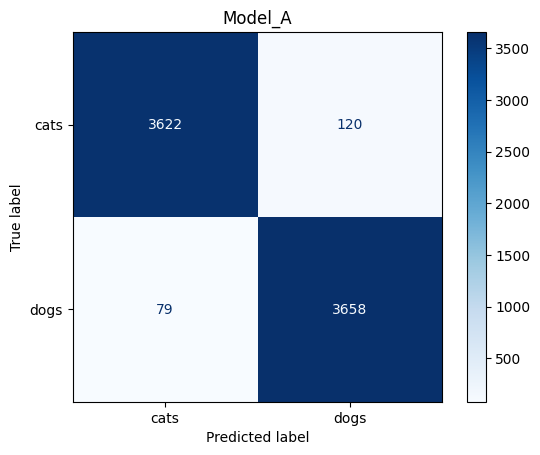

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


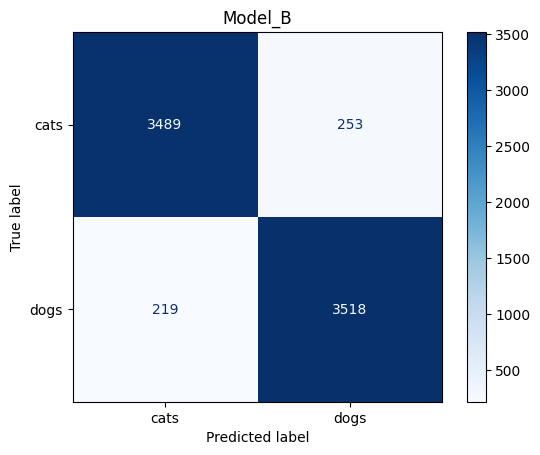

{'model': 'Model_A', 'accuracy': 0.9733921647279048, 'f1': 0.973519627411843, 'auc': np.float64(0.9970854958868993)}
{'model': 'Model_B', 'accuracy': 0.9368899585506084, 'f1': 0.9371337240277038, 'auc': np.float64(0.9846403573721523)}


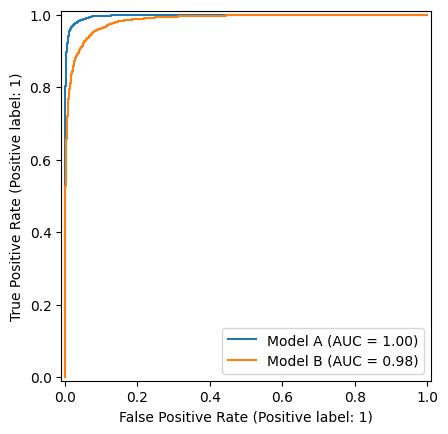

In [ ]:
if RUN_EVALUATION:
    from sklearn.metrics import (
        accuracy_score, f1_score, roc_auc_score,
        confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
    )
    import matplotlib.pyplot as plt
    import numpy as np
    import json

    def evaluate_classifier(model, ds, name):
        ys = []
        scores = []
        for imgs, targets in ds:
            scores.extend(model(imgs, training=False).numpy().reshape(-1).tolist())
            ys.extend(targets.numpy().reshape(-1).astype(int).tolist())

        ys = np.asarray(ys)
        scores = np.asarray(scores)
        pred = (scores >= 0.5).astype(int)

        values = dict(
            model=name,
            accuracy=accuracy_score(ys, pred),
            f1=f1_score(ys, pred),
            auc=roc_auc_score(ys, scores)
        )

        ConfusionMatrixDisplay(
            confusion_matrix(ys, pred),
            display_labels=['cats', 'dogs']
        ).plot(cmap='Blues')
        plt.title(name)
        plt.savefig(OUT / f'{name}_confusion.png')
        plt.show()

        return ys, scores, values

    y_a, s_a, metrics_a = evaluate_classifier(model_a, test_cls, 'Model_A')
    y_b, s_b, metrics_b = evaluate_classifier(model_b, test_b, 'Model_B')

    assert np.array_equal(y_a, y_b), 'Test order changed unexpectedly'

    print(metrics_a)
    print(metrics_b)

    plt.figure()
    RocCurveDisplay.from_predictions(y_a, s_a, name='Model A', ax=plt.gca())
    RocCurveDisplay.from_predictions(y_b, s_b, name='Model B', ax=plt.gca())
    plt.savefig(OUT / 'ROC_comparison.png')
    plt.show()

    with open(OUT / 'metrics.json', 'w') as f:
        json.dump([metrics_a, metrics_b], f, indent=2)
else:
    print("Skipped: RUN_EVALUATION disabled")

if not RUN_EVALUATION:
    with open(OUT/'metrics.json') as f:
        for result in json.load(f): print(result)


In [ ]:

from pathlib import Path
import json

required_files = [
    "model_a.keras",
    "model_b.keras",
    "sr_generator.keras",
    "metrics.json",
    "Model_A_confusion.png",
    "Model_B_confusion.png",
    "ROC_comparison.png",
    "transform_examples.png",
    "resolution_examples.png"
]

print("FINAL FILE CHECK")
print("-" * 40)

for name in required_files:
    print(
        "FOUND" if (OUT / name).exists() else "MISSING",
        name
    )

checkpoint = OUT / "gan_checkpoints" / "ckpt-150.index"
print(
    "FOUND" if checkpoint.exists() else "MISSING",
    "SRGAN Epoch 150 checkpoint"
)

print("\nDATASET SPLIT")
print("Training:", len(p_fit) + len(p_val))
print("Testing:", len(p_test))

print("\nFINAL METRICS")
with open(OUT / "metrics.json") as f:
    for result in json.load(f):
        print(result)


FINAL FILE CHECK
----------------------------------------
FOUND model_a.keras
FOUND model_b.keras
FOUND sr_generator.keras
FOUND metrics.json
FOUND Model_A_confusion.png
FOUND Model_B_confusion.png
FOUND ROC_comparison.png
FOUND transform_examples.png
FOUND resolution_examples.png
FOUND SRGAN Epoch 150 checkpoint

DATASET SPLIT
Training: 17451
Testing: 7479

FINAL METRICS
{'model': 'Model_A', 'accuracy': 0.9733921647279048, 'f1': 0.973519627411843, 'auc': 0.9970854958868993}
{'model': 'Model_B', 'accuracy': 0.9368899585506084, 'f1': 0.9371337240277038, 'auc': 0.9846403573721523}


### Experimental Results and Discussion

Both classifiers were evaluated on the same held-out test set containing 7,479 images, with cats assigned class 0 and dogs assigned class 1.

**Model A**, trained using the original 128×128 images, achieved 97.34% accuracy, an F1-score of 0.9735, and ROC-AUC of 0.9971. It correctly classified 7,280 images and misclassified 199.

**Model B**, trained using images enhanced by the SRGAN from 32×32 to 128×128 resolution, achieved 93.69% accuracy, an F1-score of 0.9371, and ROC-AUC of 0.9846. It correctly classified 7,007 images and misclassified 472.

Model A outperformed Model B across all three evaluation metrics. One possible explanation is that downsampling to 32×32 removed discriminative visual information that the SRGAN could not fully reconstruct. Additionally, super-resolution may introduce reconstructed textures or artifacts that affect classification.

These findings suggest that although super-resolution can improve the apparent resolution of low-resolution images, it does not necessarily improve classification accuracy compared with using the original high-resolution images.

The results are specific to this dataset, SRGAN architecture, and training configuration.